# 07 · Validación contra Datos Reales — Savia Salud EPS

**Objetivo:** Validar el modelo XGBoost entrenado comparando sus predicciones contra:
1. **Etiquetas reales** (resultado de auditoría)
2. **Etiquetado IA previo** de Savia (`ejecucion_glosa_aut_ia` en `cm_facturas`)

## Estrategia de validación

| Validación | Datos | Periodo | Propósito |
|---|---|---|---|
| **A — Test set** | Muestra aleatoria del test split | jun-jul 2025 | Confirmar métricas reportadas + comparar vs IA Savia |
| **B — Out-of-time** | Datos frescos de la BD | ago-dic 2025 | Validar generalización a datos NO vistos en entrenamiento |

## Columnas clave de la BD
- `ejecucion_glosa_aut_ia`: Predicción del sistema IA anterior de Savia
- `estado_glosa_aut`: Estado de la glosa automática
- Target real: construido desde `cm_auditoria_devoluciones` y `cm_auditoria_motivos_glosas`

**Entrada:** test split + BD `system_savia`  
**Salida:** `reports/evaluations/20260310_validacion_datos_reales.json` + figuras

In [1]:
# Celda 1 — Configuración, imports, conexión BD y carga del modelo
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    recall_score, precision_score, roc_auc_score, balanced_accuracy_score
)
from sqlalchemy import create_engine, text
from pathlib import Path
import json
import time
import warnings
warnings.filterwarnings('ignore')

# ── Configuración de gráficos ─────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': 300, 'font.size': 11,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'figure.facecolor': 'white', 'axes.facecolor': '#f8f9fa',
    'axes.grid': True, 'grid.alpha': 0.4,
})

PALETTE = {0: '#27ae60', 1: '#e67e22', 2: '#e74c3c'}
LABELS  = {0: 'Auditada', 1: 'Glosada', 2: 'Devuelta'}
COLORS  = [PALETTE[k] for k in sorted(PALETTE)]
RANDOM_STATE = 42

# ── Rutas ──────────────────────────────────────────────────────
BASE_DIR      = Path(r'D:\Users\jcardonr\Documents\eafit\Codigo')
DATA_DIR      = BASE_DIR / 'data' / 'processed'
MODELS_DIR    = BASE_DIR / 'models' / 'artifacts'
FIGURES_DIR   = BASE_DIR / 'reports' / 'figures'
EVAL_DIR      = BASE_DIR / 'reports' / 'evaluations'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name: str):
    path = FIGURES_DIR / name
    plt.savefig(path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f'  Guardado: {path.name}')

# ── Conexión BD ────────────────────────────────────────────────
user, password, host, db_name, port = (
    "jcardonr", "6nxx2yVWaKXyiF1cZbfS*", "10.250.5.36", "system_savia", "3306"
)
engine = create_engine(
    f"mysql+pymysql://{user}:{password}@{host}:{port}/{db_name}",
    connect_args={"connect_timeout": 60},
    pool_recycle=3600,
)
with engine.connect() as conn:
    conn.execute(text("SELECT 1"))
print("✅ Conexión BD exitosa")

# ── Cargar modelo XGBoost ──────────────────────────────────────
model_path = MODELS_DIR / '20260309_xgboost_v1.json'
model = xgb.Booster()
model.load_model(str(model_path))
print(f"✅ Modelo cargado: {model_path.name}")

# ── Cargar lista de features ──────────────────────────────────
feature_list_path = DATA_DIR / '20260309_feature_list.txt'
with open(feature_list_path) as f:
    FEATURE_COLS = [line.strip() for line in f if line.strip()]
print(f"✅ Features: {len(FEATURE_COLS)}")
print(f"\n🎯 Listo para validación — {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M')}")

✅ Conexión BD exitosa
✅ Modelo cargado: 20260309_xgboost_v1.json
✅ Features: 48

🎯 Listo para validación — 2026-03-10 13:53


## Parte A — Validación sobre Test Set con IA Previa de Savia

In [2]:
# Celda 2 — Cargar test set y tomar muestra aleatoria
# El test set (jun-jul 2025) tiene 40,193 filas con labels reales y features.
# Tomamos una muestra estratificada de ~5,000 facturas para la comparación triple.

df_test = pd.read_parquet(DATA_DIR / '20260309_test.parquet')
print(f"Test set cargado: {len(df_test):,} filas × {len(df_test.columns)} cols")
print(f"Distribución target:")
for cls, cnt in df_test['target'].value_counts().sort_index().items():
    print(f"  {LABELS[cls]}: {cnt:,} ({cnt/len(df_test)*100:.1f}%)")

# Muestra estratificada de 5,000 facturas (proporcional a cada clase)
SAMPLE_SIZE = 5_000
samples = []
for cls in sorted(df_test['target'].unique()):
    group = df_test[df_test['target'] == cls]
    n = min(len(group), int(SAMPLE_SIZE * len(group) / len(df_test)))
    samples.append(group.sample(n=n, random_state=RANDOM_STATE))
df_sample = pd.concat(samples, ignore_index=True)

print(f"\n📊 Muestra estratificada: {len(df_sample):,} facturas")
for cls, cnt in df_sample['target'].value_counts().sort_index().items():
    print(f"  {LABELS[cls]}: {cnt:,} ({cnt/len(df_sample)*100:.1f}%)")

# Extraer factura_ids para la consulta a BD
sample_ids = df_sample['factura_id'].tolist()
print(f"\nFactura IDs extraídos: {len(sample_ids):,}")

Test set cargado: 40,193 filas × 50 cols
Distribución target:
  Auditada: 13,723 (34.1%)
  Glosada: 16,143 (40.2%)
  Devuelta: 10,327 (25.7%)

📊 Muestra estratificada: 4,999 facturas
  Auditada: 1,707 (34.1%)
  Glosada: 2,008 (40.2%)
  Devuelta: 1,284 (25.7%)

Factura IDs extraídos: 4,999


In [5]:
# Celda 3 — Consultar etiquetas IA previa de Savia desde BD
# Las columnas ejecucion_glosa_aut_ia y estado_glosa_aut fueron EXCLUIDAS
# del dataset de entrenamiento por ser data leakage. Ahora las consultamos
# para comparar la IA previa de Savia vs nuestro modelo.

print("Consultando etiquetas IA previa de Savia para la muestra...")

ids_str = ",".join(str(x) for x in sample_ids)
q_ia_previa = text(f"""
SELECT
    f.id                       AS factura_id,
    f.ejecucion_glosa_aut_ia,
    f.estado_glosa_aut
FROM cm_facturas f
WHERE f.id IN ({ids_str})
""")

t0 = time.time()
with engine.connect() as conn:
    df_ia_previa = pd.DataFrame(conn.execute(q_ia_previa).fetchall())
if not df_ia_previa.empty:
    df_ia_previa.columns = ['factura_id', 'ejecucion_glosa_aut_ia', 'estado_glosa_aut']
print(f"✅ Consulta completada en {time.time()-t0:.1f}s → {len(df_ia_previa):,} filas")

# Explorar valores únicos de las columnas IA previa
print(f"\n── ejecucion_glosa_aut_ia ──")
print(df_ia_previa['ejecucion_glosa_aut_ia'].value_counts(dropna=False).head(20))

print(f"\n── estado_glosa_aut ──")
print(df_ia_previa['estado_glosa_aut'].value_counts(dropna=False).head(20))

# Merge con la muestra
df_sample = df_sample.merge(df_ia_previa, on='factura_id', how='left')
n_con_ia = df_sample['ejecucion_glosa_aut_ia'].notna().sum()
print(f"\nFacturas con etiqueta IA previa: {n_con_ia:,} de {len(df_sample):,} ({n_con_ia/len(df_sample)*100:.1f}%)")

Consultando etiquetas IA previa de Savia para la muestra...
✅ Consulta completada en 15.0s → 4,999 filas

── ejecucion_glosa_aut_ia ──
ejecucion_glosa_aut_ia
0    4999
Name: count, dtype: int64

── estado_glosa_aut ──
estado_glosa_aut
0    4999
Name: count, dtype: int64

Facturas con etiqueta IA previa: 4,999 de 4,999 (100.0%)


In [6]:
# Celda 4 — Mapear IA previa a nuestro esquema de 3 clases + predicciones del modelo
#
# Mapeo de ejecucion_glosa_aut_ia / estado_glosa_aut al esquema {0, 1, 2}:
#   - Si contiene "glosa" o "glosar" → 1 (Glosada)
#   - Si contiene "devol" → 2 (Devuelta)
#   - Si contiene "audit" o "pagar" o es NULL/vacío → 0 (Auditada)
# NOTA: Este mapeo se ajustará después de ver los valores reales en celda 3.

def mapear_ia_previa(row):
    """Mapea las columnas de IA previa de Savia a nuestro esquema de 3 clases."""
    val_ia = str(row.get('ejecucion_glosa_aut_ia', '') or '').lower().strip()
    val_estado = str(row.get('estado_glosa_aut', '') or '').lower().strip()

    # Combinar ambas columnas para mayor cobertura
    combinado = f"{val_ia} {val_estado}"

    if 'devol' in combinado or 'devuelt' in combinado:
        return 2  # Devuelta
    elif 'glos' in combinado:
        return 1  # Glosada
    elif 'audit' in combinado or 'pagar' in combinado or 'pago' in combinado:
        return 0  # Auditada
    elif val_ia in ('', 'nan', 'none', 'null') and val_estado in ('', 'nan', 'none', 'null'):
        return -1  # Sin predicción IA previa
    else:
        return 0  # Por defecto Auditada (si hay valor no reconocido)

df_sample['pred_ia_previa'] = df_sample.apply(mapear_ia_previa, axis=1)

print("── Mapeo IA Previa → esquema 3 clases ──")
print(df_sample['pred_ia_previa'].value_counts().sort_index())
n_sin_ia = (df_sample['pred_ia_previa'] == -1).sum()
print(f"\nFacturas sin predicción IA previa: {n_sin_ia:,} ({n_sin_ia/len(df_sample)*100:.1f}%)")

# ── Predicciones de nuestro modelo XGBoost ────────────────────
X_sample = df_sample[FEATURE_COLS].values
dmatrix = xgb.DMatrix(X_sample, feature_names=FEATURE_COLS)
proba = model.predict(dmatrix)  # Probabilidades por clase
df_sample['pred_modelo'] = proba.argmax(axis=1)

print(f"\n── Predicciones del modelo XGBoost ──")
print(df_sample['pred_modelo'].value_counts().sort_index())

# ── Resumen comparativo ──────────────────────────────────────
print(f"\n{'='*60}")
print(f"RESUMEN DE PREDICCIONES (n={len(df_sample):,})")
print(f"{'='*60}")
for cls in [0, 1, 2]:
    n_real = (df_sample['target'] == cls).sum()
    n_modelo = (df_sample['pred_modelo'] == cls).sum()
    n_ia = (df_sample['pred_ia_previa'] == cls).sum()
    print(f"  {LABELS[cls]:10s}  Real: {n_real:>5,}  Modelo: {n_modelo:>5,}  IA Previa: {n_ia:>5,}")

── Mapeo IA Previa → esquema 3 clases ──
pred_ia_previa
0    4999
Name: count, dtype: int64

Facturas sin predicción IA previa: 0 (0.0%)

── Predicciones del modelo XGBoost ──
pred_modelo
0    1975
1    1821
2    1203
Name: count, dtype: int64

RESUMEN DE PREDICCIONES (n=4,999)
  Auditada    Real: 1,707  Modelo: 1,975  IA Previa: 4,999
  Glosada     Real: 2,008  Modelo: 1,821  IA Previa:     0
  Devuelta    Real: 1,284  Modelo: 1,203  IA Previa:     0


In [7]:
# Celda 5 — Métricas de comparación triple: Real vs Modelo vs IA Previa
# Para la comparación con IA previa, usamos solo facturas que SÍ tienen predicción IA.

y_true = df_sample['target'].values
y_modelo = df_sample['pred_modelo'].values

# Filtrar facturas con predicción IA previa válida
mask_ia = df_sample['pred_ia_previa'] >= 0
y_true_ia = df_sample.loc[mask_ia, 'target'].values
y_ia = df_sample.loc[mask_ia, 'pred_ia_previa'].values
y_modelo_ia = df_sample.loc[mask_ia, 'pred_modelo'].values

print("=" * 70)
print("MÉTRICAS — NUESTRO MODELO vs REALIDAD (muestra completa)")
print("=" * 70)
print(classification_report(y_true, y_modelo, target_names=[LABELS[i] for i in [0,1,2]], digits=4))

f1_modelo = f1_score(y_true, y_modelo, average='macro')
recall_glosada_modelo = recall_score(y_true, y_modelo, average=None)[1]
bal_acc_modelo = balanced_accuracy_score(y_true, y_modelo)
print(f"F1-macro: {f1_modelo:.4f}")
print(f"Recall Glosada: {recall_glosada_modelo:.4f}")
print(f"Balanced Accuracy: {bal_acc_modelo:.4f}")

if mask_ia.sum() > 0:
    print(f"\n{'='*70}")
    print(f"MÉTRICAS — IA PREVIA SAVIA vs REALIDAD (n={mask_ia.sum():,} con predicción)")
    print("=" * 70)
    print(classification_report(y_true_ia, y_ia, target_names=[LABELS[i] for i in [0,1,2]], digits=4))

    f1_ia = f1_score(y_true_ia, y_ia, average='macro')
    recall_glosada_ia = recall_score(y_true_ia, y_ia, average=None)[1]
    bal_acc_ia = balanced_accuracy_score(y_true_ia, y_ia)
    print(f"F1-macro: {f1_ia:.4f}")
    print(f"Recall Glosada: {recall_glosada_ia:.4f}")
    print(f"Balanced Accuracy: {bal_acc_ia:.4f}")

    # Comparación directa en el mismo subconjunto
    print(f"\n{'='*70}")
    print("COMPARACIÓN DIRECTA (mismo subconjunto de facturas con IA previa)")
    print("=" * 70)
    f1_modelo_sub = f1_score(y_true_ia, y_modelo_ia, average='macro')
    recall_glosada_modelo_sub = recall_score(y_true_ia, y_modelo_ia, average=None)[1]

    print(f"                    Nuestro Modelo    IA Previa Savia    Δ (Modelo - IA)")
    print(f"  F1-macro:         {f1_modelo_sub:.4f}            {f1_ia:.4f}              {f1_modelo_sub - f1_ia:+.4f}")
    print(f"  Recall Glosada:   {recall_glosada_modelo_sub:.4f}            {recall_glosada_ia:.4f}              {recall_glosada_modelo_sub - recall_glosada_ia:+.4f}")
else:
    print("\n⚠️ No hay facturas con predicción IA previa — saltando comparación")
    f1_ia = recall_glosada_ia = bal_acc_ia = None

MÉTRICAS — NUESTRO MODELO vs REALIDAD (muestra completa)
              precision    recall  f1-score   support

    Auditada     0.6451    0.7463    0.6920      1707
     Glosada     0.7946    0.7206    0.7558      2008
    Devuelta     0.8080    0.7570    0.7817      1284

    accuracy                         0.7387      4999
   macro avg     0.7492    0.7413    0.7432      4999
weighted avg     0.7470    0.7387    0.7407      4999

F1-macro: 0.7432
Recall Glosada: 0.7206
Balanced Accuracy: 0.7413

MÉTRICAS — IA PREVIA SAVIA vs REALIDAD (n=4,999 con predicción)
              precision    recall  f1-score   support

    Auditada     0.3415    1.0000    0.5091      1707
     Glosada     0.0000    0.0000    0.0000      2008
    Devuelta     0.0000    0.0000    0.0000      1284

    accuracy                         0.3415      4999
   macro avg     0.1138    0.3333    0.1697      4999
weighted avg     0.1166    0.3415    0.1738      4999

F1-macro: 0.1697
Recall Glosada: 0.0000
Balanced A

  Guardado: val_01_confusion_matrices_comparacion.png


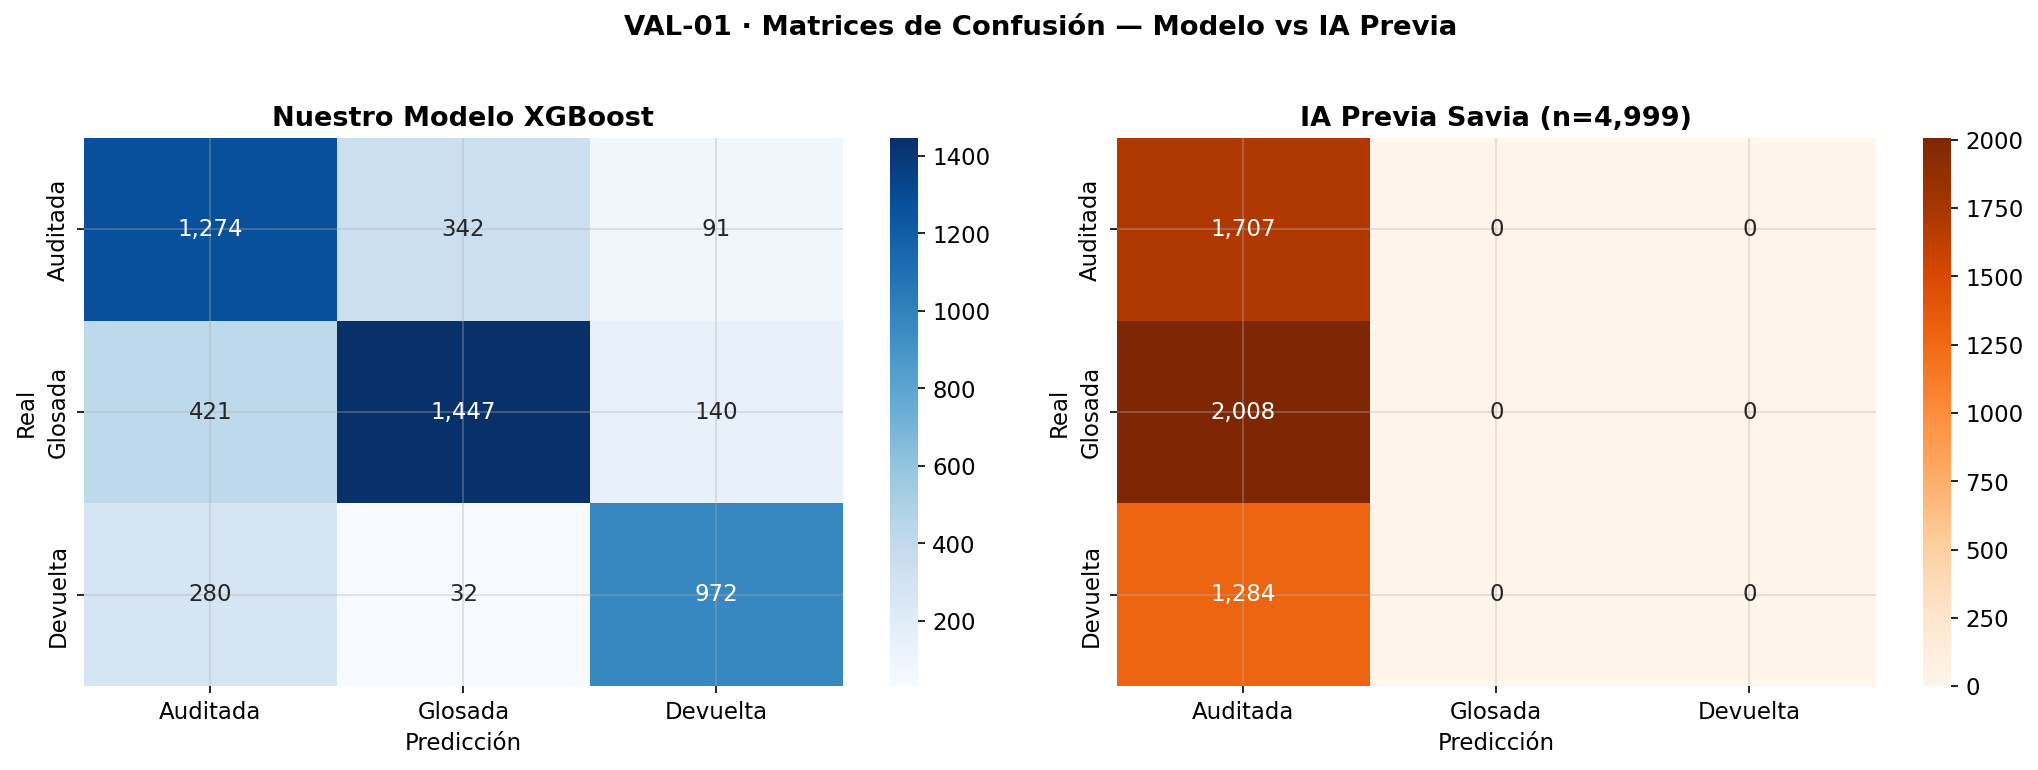

  Guardado: val_02_metricas_por_clase_comparacion.png


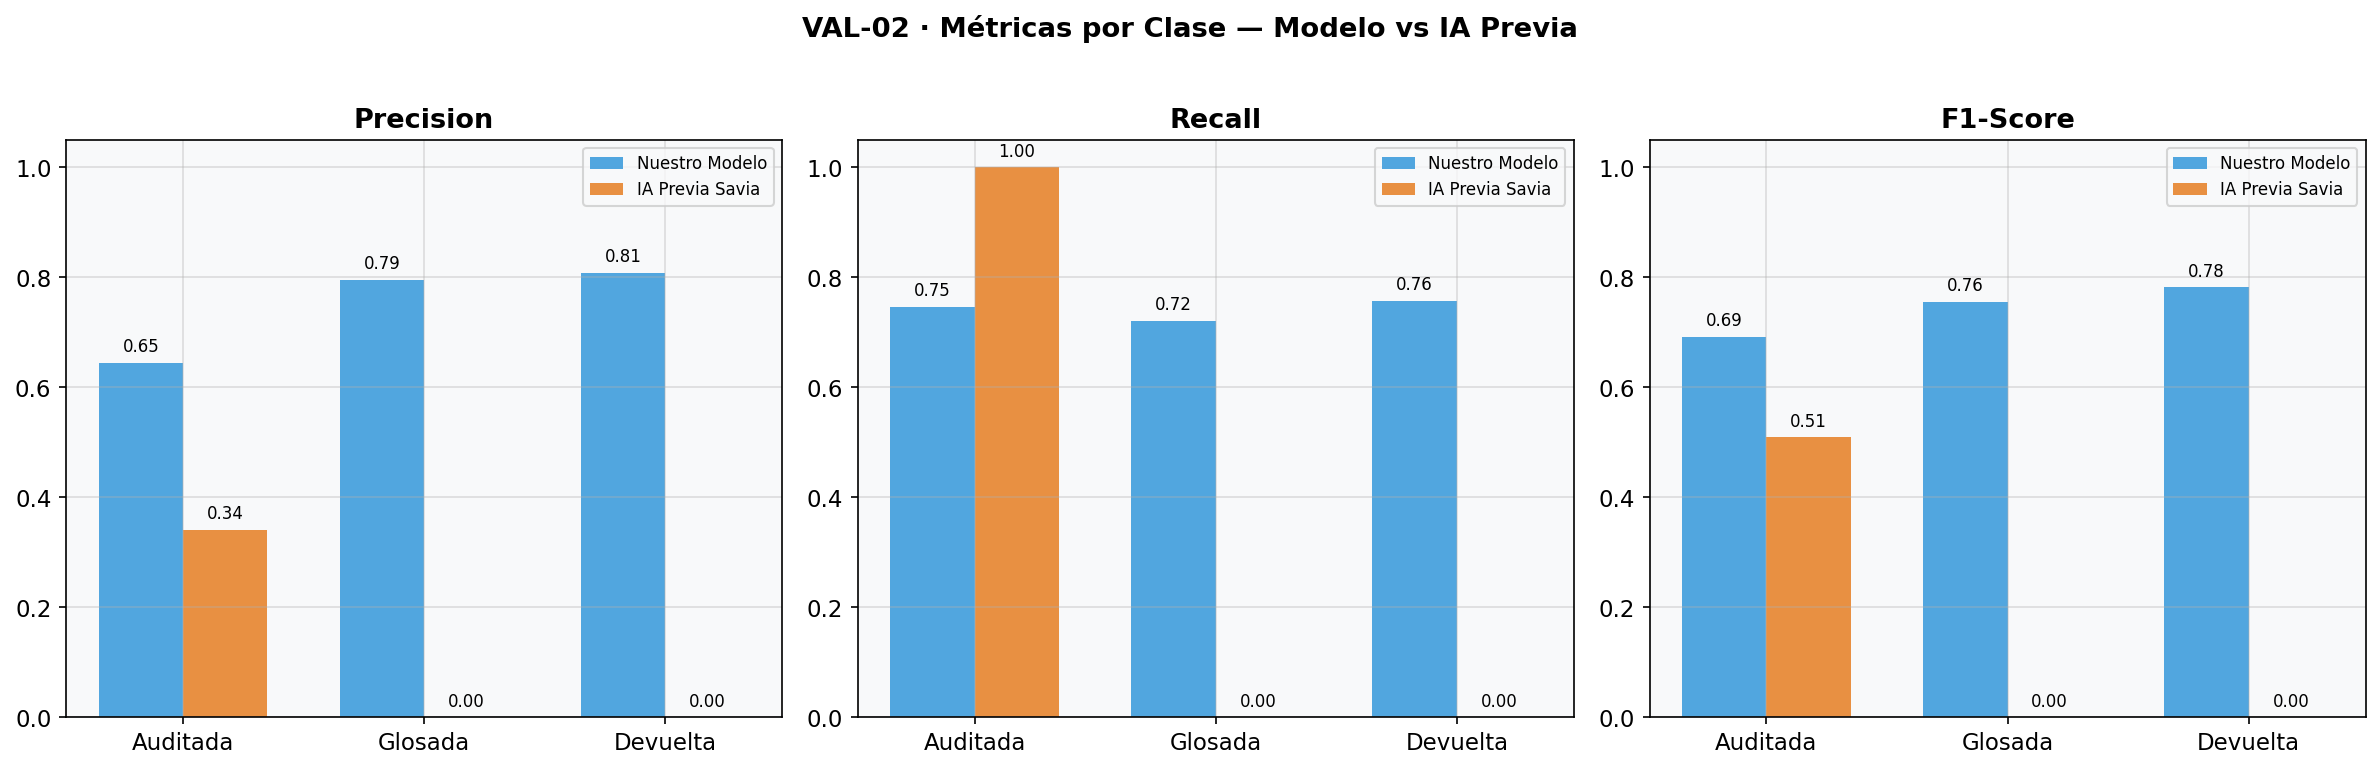

In [8]:
# Celda 6 — Visualización: Matrices de confusión lado a lado + barras comparativas

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
class_names = [LABELS[i] for i in [0, 1, 2]]

# ── Confusion Matrix: Nuestro Modelo ──
cm_modelo = confusion_matrix(y_true, y_modelo)
sns.heatmap(cm_modelo, annot=True, fmt=',d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Nuestro Modelo XGBoost')
axes[0].set_ylabel('Real')
axes[0].set_xlabel('Predicción')

# ── Confusion Matrix: IA Previa Savia ──
if mask_ia.sum() > 0:
    cm_ia = confusion_matrix(y_true_ia, y_ia)
    sns.heatmap(cm_ia, annot=True, fmt=',d', cmap='Oranges',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title(f'IA Previa Savia (n={mask_ia.sum():,})')
    axes[1].set_ylabel('Real')
    axes[1].set_xlabel('Predicción')
else:
    axes[1].text(0.5, 0.5, 'Sin datos IA previa', ha='center', va='center',
                 fontsize=14, transform=axes[1].transAxes)
    axes[1].set_title('IA Previa Savia')

plt.suptitle('VAL-01 · Matrices de Confusión — Modelo vs IA Previa', fontweight='bold', y=1.02)
plt.tight_layout()
save_fig('val_01_confusion_matrices_comparacion.png')
plt.show()

# ── Barras comparativas de métricas por clase ─────────────────
if mask_ia.sum() > 0:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    metrics_data = {}
    for metric_name, metric_fn in [('Precision', precision_score),
                                    ('Recall', recall_score),
                                    ('F1-Score', f1_score)]:
        vals_modelo = metric_fn(y_true_ia, y_modelo_ia, average=None)
        vals_ia = metric_fn(y_true_ia, y_ia, average=None)
        metrics_data[metric_name] = {'Modelo': vals_modelo, 'IA Previa': vals_ia}

    for idx, (metric_name, data) in enumerate(metrics_data.items()):
        ax = axes[idx]
        x = np.arange(3)
        width = 0.35
        bars1 = ax.bar(x - width/2, data['Modelo'], width, label='Nuestro Modelo',
                       color='#3498db', alpha=0.85)
        bars2 = ax.bar(x + width/2, data['IA Previa'], width, label='IA Previa Savia',
                       color='#e67e22', alpha=0.85)
        ax.set_xticks(x)
        ax.set_xticklabels(class_names)
        ax.set_title(metric_name)
        ax.set_ylim(0, 1.05)
        ax.legend(fontsize=8)

        # Anotar valores
        for bar in bars1:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                    f'{bar.get_height():.2f}', ha='center', fontsize=8)
        for bar in bars2:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                    f'{bar.get_height():.2f}', ha='center', fontsize=8)

    plt.suptitle('VAL-02 · Métricas por Clase — Modelo vs IA Previa', fontweight='bold', y=1.02)
    plt.tight_layout()
    save_fig('val_02_metricas_por_clase_comparacion.png')
    plt.show()

## Parte B — Validación Out-of-Time (ago-dic 2025)

Facturas radicadas entre agosto y diciembre 2025 **no fueron vistas en entrenamiento** (right-censoring).  
Ahora en marzo 2026, sus auditorías deberían estar completas → labels reales disponibles.

Se reconstruyen las features usando el mismo pipeline de FE (notebook 04) y se predicen con el modelo.

In [12]:
# Celda 7 — Extraer datos out-of-time (ago-dic 2025) desde la BD
# Reproduce los pasos 1-5 del notebook 02 para el periodo ago-dic 2025.

print("=" * 70)
print("PARTE B: EXTRACCIÓN OUT-OF-TIME (ago-dic 2025)")
print("=" * 70)

OOT_START = '2025-08-01'
OOT_END   = '2026-01-01'  # Exclusivo

def query_to_df(sql_str):
    """Ejecuta query y retorna DataFrame."""
    with engine.connect() as conn:
        result = conn.execute(text(sql_str))
        cols = list(result.keys())
        rows = result.fetchall()
        return pd.DataFrame(rows, columns=cols)

# Clase 2: Devuelta
print("  Clase 2 (Devuelta)...")
t0 = time.time()
df_dev = query_to_df(f"""
SELECT DISTINCT f.id AS factura_id, 2 AS target
FROM cm_facturas f
INNER JOIN cm_auditoria_devoluciones cad ON cad.cm_facturas_id = f.id
WHERE f.fecha_radicacion >= '{OOT_START}' AND f.fecha_radicacion < '{OOT_END}'
""")
print(f"    → {len(df_dev):,} facturas ({time.time()-t0:.1f}s)")

# Clase 1: Glosada (no en Devueltas)
print("  Clase 1 (Glosada)...")
t0 = time.time()
df_glo = query_to_df(f"""
SELECT DISTINCT f.id AS factura_id, 1 AS target
FROM cm_facturas f
INNER JOIN cm_detalles cd ON cd.cm_facturas_id = f.id
INNER JOIN cm_auditoria_motivos_glosas camg ON camg.cm_detalles_id = cd.id
WHERE f.fecha_radicacion >= '{OOT_START}' AND f.fecha_radicacion < '{OOT_END}'
  AND f.id NOT IN (SELECT cm_facturas_id FROM cm_auditoria_devoluciones WHERE cm_facturas_id IS NOT NULL)
LIMIT 200000
""")
print(f"    → {len(df_glo):,} facturas ({time.time()-t0:.1f}s)")

# Clase 0: Auditada (ni Devuelta ni Glosada, submuestreo 1/20)
print("  Clase 0 (Auditada, muestreo 1/20)...")
t0 = time.time()
df_aud = query_to_df(f"""
SELECT f.id AS factura_id, 0 AS target
FROM cm_facturas f
WHERE f.fecha_radicacion >= '{OOT_START}' AND f.fecha_radicacion < '{OOT_END}'
  AND NOT EXISTS (SELECT 1 FROM cm_auditoria_devoluciones cad WHERE cad.cm_facturas_id = f.id)
  AND NOT EXISTS (SELECT 1 FROM cm_detalles cd
                   INNER JOIN cm_auditoria_motivos_glosas camg ON camg.cm_detalles_id = cd.id
                   WHERE cd.cm_facturas_id = f.id)
  AND MOD(f.id, 20) = 0
LIMIT 200000
""")
print(f"    → {len(df_aud):,} facturas ({time.time()-t0:.1f}s)")

df_oot_ids = pd.concat([df_dev, df_glo, df_aud], ignore_index=True)
df_oot_ids = df_oot_ids.drop_duplicates(subset=['factura_id'], keep='first')

print(f"\n✅ Total OOT facturas: {len(df_oot_ids):,}")
for cls, cnt in df_oot_ids['target'].value_counts().sort_index().items():
    print(f"  {LABELS[cls]}: {cnt:,} ({cnt/len(df_oot_ids)*100:.1f}%)")

if len(df_glo) == 0:
    print("\n⚠️ ALERTA: 0 facturas glosadas en el periodo OOT.")
    print("  Posible causa: las auditorías aún no se han completado.")
    print("  La validación OOT puede no ser confiable.")

PARTE B: EXTRACCIÓN OUT-OF-TIME (ago-dic 2025)
  Clase 2 (Devuelta)...
    → 24,230 facturas (2.0s)
  Clase 1 (Glosada)...
    → 150,871 facturas (79.4s)
  Clase 0 (Auditada, muestreo 1/20)...
    → 48,520 facturas (3.0s)

✅ Total OOT facturas: 223,621
  Auditada: 48,520 (21.7%)
  Glosada: 150,871 (67.5%)
  Devuelta: 24,230 (10.8%)


In [13]:
# Celda 8 — Extraer features OOT desde la BD

oot_ids = tuple(df_oot_ids['factura_id'].tolist())
CHUNK_SIZE = 50_000
chunks = [oot_ids[i:i+CHUNK_SIZE] for i in range(0, len(oot_ids), CHUNK_SIZE)]
print(f"IDs OOT: {len(oot_ids):,} | Chunks: {len(chunks)}")

with engine.connect() as conn:
    # ── Paso 2: Features de cm_facturas ──────────────────────────
    print("\n── Features cm_facturas ──")
    feat_list = []
    for i, chunk in enumerate(chunks):
        ids_str = ",".join(str(x) for x in chunk)
        q = text(f"""
        SELECT f.id AS factura_id, f.nit AS nit_prestador,
               f.mae_tipo_contrato_valor AS tipo_contrato,
               f.mae_regimen_valor AS regimen,
               f.valor_factura, f.valor_copago, f.valor_cuota_moderadora,
               f.fecha_prestacion, f.fecha_radicacion,
               DATEDIFF(DATE(f.fecha_radicacion), DATE(f.fecha_prestacion)) AS dias_hasta_radicacion,
               f.cm_fe_rips_cargas_id,
               f.ejecucion_glosa_aut_ia, f.estado_glosa_aut,
               MONTH(f.fecha_radicacion) AS mes_radicacion,
               QUARTER(f.fecha_radicacion) AS trimestre_radicacion,
               YEAR(f.fecha_radicacion) AS anio_radicacion
        FROM cm_facturas f WHERE f.id IN ({ids_str})
        """)
        result = conn.execute(q)
        df_chunk = pd.DataFrame(result.fetchall(), columns=list(result.keys()))
        feat_list.append(df_chunk)
        print(f"  Chunk {i+1}/{len(chunks)}: {len(df_chunk):,}")
    df_oot_feat = pd.concat(feat_list, ignore_index=True)
    print(f"  Total: {len(df_oot_feat):,}")

    # ── Paso 3: Features agregadas de cm_detalles ────────────────
    print("\n── Features cm_detalles ──")
    det_list = []
    for i, chunk in enumerate(chunks):
        ids_str = ",".join(str(x) for x in chunk)
        q = text(f"""
        SELECT cd.cm_facturas_id AS factura_id,
               COUNT(*) AS num_items,
               COUNT(DISTINCT cd.ma_servicio_codigo) AS num_cups_distintos,
               COUNT(DISTINCT NULLIF(SUBSTRING_INDEX(cd.nombre_dx, '-', 1), '')) AS num_dx_distintos,
               SUM(cd.valor_facturado) AS sum_valor_facturado,
               MAX(cd.valor_facturado) AS max_valor_item,
               AVG(cd.valor_facturado) AS avg_valor_item,
               SUM(CASE WHEN cd.aplica_autorizacion = 1 THEN 1 ELSE 0 END) AS num_items_con_autorizacion,
               COUNT(DISTINCT cd.tipo_servicio) AS num_tipos_servicio
        FROM cm_detalles cd WHERE cd.cm_facturas_id IN ({ids_str})
        GROUP BY cd.cm_facturas_id
        """)
        result = conn.execute(q)
        df_chunk = pd.DataFrame(result.fetchall(), columns=list(result.keys()))
        det_list.append(df_chunk)
        print(f"  Chunk {i+1}/{len(chunks)}: {len(df_chunk):,}")
    df_oot_det = pd.concat(det_list, ignore_index=True)
    print(f"  Total: {len(df_oot_det):,}")

    # ── Paso 4: Features del prestador (global, últimos 24 meses) ──
    print("\n── Features prestador ──")
    nits = df_oot_feat['nit_prestador'].dropna().unique()
    nits_str = "'" + "','".join(str(n) for n in nits) + "'"

    q_prov = text(f"""
    SELECT f.nit AS nit_prestador,
           COUNT(DISTINCT f.id) AS total_facturas_nit,
           ROUND(COUNT(DISTINCT cad.cm_facturas_id)*100.0/NULLIF(COUNT(DISTINCT f.id),0),2) AS tasa_devolucion_nit,
           ROUND(AVG(f.valor_factura),0) AS valor_promedio_nit,
           ROUND(AVG(DATEDIFF(DATE(f.fecha_radicacion), DATE(f.fecha_prestacion))),1) AS dias_radicacion_promedio_nit
    FROM cm_facturas f
    LEFT JOIN cm_auditoria_devoluciones cad ON cad.cm_facturas_id = f.id
    WHERE f.fecha_radicacion >= DATE_SUB(NOW(), INTERVAL 24 MONTH) AND f.nit IN ({nits_str})
    GROUP BY f.nit
    """)
    t0 = time.time()
    result = conn.execute(q_prov)
    df_prov = pd.DataFrame(result.fetchall(), columns=list(result.keys()))
    print(f"  {len(df_prov):,} NITs ({time.time()-t0:.1f}s)")

    q_tg = text(f"""
    SELECT f.nit AS nit_prestador,
           COUNT(DISTINCT f.id) AS facturas_con_glosa_nit
    FROM cm_facturas f
    INNER JOIN (SELECT cd.cm_facturas_id FROM cm_detalles cd
                INNER JOIN cm_auditoria_motivos_glosas camg ON camg.cm_detalles_id = cd.id
                GROUP BY cd.cm_facturas_id) g ON g.cm_facturas_id = f.id
    WHERE f.fecha_radicacion >= DATE_SUB(NOW(), INTERVAL 24 MONTH) AND f.nit IN ({nits_str})
    GROUP BY f.nit
    """)
    t0 = time.time()
    result = conn.execute(q_tg)
    df_tg = pd.DataFrame(result.fetchall(), columns=list(result.keys()))
    print(f"  Tasa glosa: {len(df_tg):,} NITs ({time.time()-t0:.1f}s)")

df_prov = df_prov.merge(df_tg, on='nit_prestador', how='left')
df_prov['tasa_glosa_nit'] = (
    df_prov['facturas_con_glosa_nit'].fillna(0) * 100
    / df_prov['total_facturas_nit'].replace(0, np.nan)
).round(2)

print(f"\n✅ Extracción OOT completada")

IDs OOT: 223,621 | Chunks: 5

── Features cm_facturas ──
  Chunk 1/5: 50,000
  Chunk 2/5: 50,000
  Chunk 3/5: 50,000
  Chunk 4/5: 50,000
  Chunk 5/5: 23,621
  Total: 223,621

── Features cm_detalles ──
  Chunk 1/5: 49,982
  Chunk 2/5: 50,000
  Chunk 3/5: 50,000
  Chunk 4/5: 50,000
  Chunk 5/5: 23,621
  Total: 223,603

── Features prestador ──
  611 NITs (106.2s)
  Tasa glosa: 587 NITs (984.6s)

✅ Extracción OOT completada


In [15]:
# Celda 9 — Ensamblar dataset OOT + Feature Engineering (mismo pipeline que notebook 04)

# ── Ensamblar ─────────────────────────────────────────────────
df_oot = df_oot_ids.merge(df_oot_feat, on='factura_id', how='left')
df_oot = df_oot.merge(df_oot_det, on='factura_id', how='left')
df_oot = df_oot.merge(
    df_prov[['nit_prestador', 'total_facturas_nit', 'tasa_devolucion_nit',
             'tasa_glosa_nit', 'valor_promedio_nit', 'dias_radicacion_promedio_nit']],
    on='nit_prestador', how='left'
)

# ── Convertir columnas Decimal a float (MySQL retorna decimal.Decimal) ──
NUMERIC_COLS = ['valor_factura', 'valor_copago', 'valor_cuota_moderadora',
                'dias_hasta_radicacion', 'num_items', 'num_cups_distintos',
                'num_dx_distintos', 'sum_valor_facturado', 'max_valor_item',
                'avg_valor_item', 'num_items_con_autorizacion', 'num_tipos_servicio',
                'total_facturas_nit', 'tasa_devolucion_nit', 'tasa_glosa_nit',
                'valor_promedio_nit', 'dias_radicacion_promedio_nit',
                'mes_radicacion', 'trimestre_radicacion', 'anio_radicacion']
for col in NUMERIC_COLS:
    if col in df_oot.columns:
        df_oot[col] = pd.to_numeric(df_oot[col], errors='coerce')

# Features derivadas (igual que notebook 02, celda 6)
df_oot['porcentaje_mayor_item'] = (
    df_oot['max_valor_item'] / df_oot['valor_factura'].replace(0, np.nan)
).clip(upper=1.0).round(4).fillna(0)
df_oot['discrepancia_valor'] = (df_oot['sum_valor_facturado'] - df_oot['valor_factura']).abs()
df_oot['tiene_fev'] = df_oot['cm_fe_rips_cargas_id'].notna().astype(int)
df_oot['dias_hasta_radicacion'] = df_oot['dias_hasta_radicacion'].clip(lower=0, upper=365)

# Encodings
df_oot['tipo_contrato_encoded'] = df_oot['tipo_contrato'].map(
    {'CAPITA': 0, 'Evento': 1, 'EVENTO': 1, 'Paquete': 2, 'PAQUETE': 2}
).fillna(-1).astype(int)
df_oot['regimen_encoded'] = df_oot['regimen'].map(
    {'SUBSIDIADO': 0, 'CONTRIBUTIVO': 1}
).fillna(-1).astype(int)

# Imputar nulos numéricos con 0
DETAIL_COLS = ['num_items', 'num_cups_distintos', 'num_dx_distintos',
               'sum_valor_facturado', 'max_valor_item', 'avg_valor_item',
               'num_items_con_autorizacion', 'num_tipos_servicio']
for col in DETAIL_COLS:
    if col in df_oot.columns:
        df_oot[col] = df_oot[col].fillna(0)

NIT_COLS = ['total_facturas_nit', 'tasa_devolucion_nit', 'tasa_glosa_nit',
            'valor_promedio_nit', 'dias_radicacion_promedio_nit']
for col in NIT_COLS:
    if col in df_oot.columns:
        df_oot[col] = df_oot[col].fillna(df_oot[col].median())

# ── Feature Engineering (mismo que notebook 04) ──────────────
# log1p
LOG_COLS = ['valor_factura', 'valor_copago', 'valor_cuota_moderadora', 'num_items',
            'num_cups_distintos', 'num_dx_distintos', 'sum_valor_facturado',
            'max_valor_item', 'avg_valor_item', 'num_items_con_autorizacion',
            'total_facturas_nit', 'valor_promedio_nit', 'discrepancia_valor']
for col in LOG_COLS:
    if col in df_oot.columns:
        df_oot[f'log_{col}'] = np.log1p(df_oot[col].astype(float))

# Flags
df_oot['is_extemporanea'] = (df_oot['dias_hasta_radicacion'] > 22).astype(np.int8)
df_oot['tiene_copago'] = (df_oot['valor_copago'] > 0).astype(np.int8)
df_oot['tiene_cuota_mod'] = (df_oot['valor_cuota_moderadora'] > 0).astype(np.int8)
df_oot['sin_detalles'] = (df_oot['num_items'] == 0).astype(np.int8)

# Interacciones
df_oot['ratio_valor_vs_nit'] = np.where(
    df_oot['valor_promedio_nit'] > 0,
    df_oot['valor_factura'] / df_oot['valor_promedio_nit'], 0
).astype(float).clip(0, 100)
df_oot['log_valor_x_tasa_glosa'] = df_oot['log_valor_factura'] * df_oot['tasa_glosa_nit'].astype(float)
df_oot['dias_x_log_valor'] = df_oot['dias_hasta_radicacion'].astype(float) * df_oot['log_valor_factura']
df_oot['ratio_autorizacion'] = np.where(
    df_oot['num_items'] > 0,
    df_oot['num_items_con_autorizacion'] / df_oot['num_items'], 0
).astype(float).clip(0, 1)
df_oot['desviacion_dias_nit'] = np.where(
    df_oot['dias_radicacion_promedio_nit'] > 0,
    df_oot['dias_hasta_radicacion'].astype(float) / df_oot['dias_radicacion_promedio_nit'].astype(float), 1
).astype(float).clip(0, 50)
df_oot['ratio_cups_items'] = np.where(
    df_oot['num_items'] > 0,
    df_oot['num_cups_distintos'] / df_oot['num_items'], 0
).astype(float).clip(0, 1)

# Verificar que tenemos todas las features
missing_feats = [c for c in FEATURE_COLS if c not in df_oot.columns]
if missing_feats:
    print(f"⚠️ Features faltantes: {missing_feats}")
else:
    print(f"✅ Todas las {len(FEATURE_COLS)} features presentes en OOT")

# Rellenar NaN remanentes en features con 0
df_oot[FEATURE_COLS] = df_oot[FEATURE_COLS].fillna(0).astype(float)

print(f"Dataset OOT ensamblado: {len(df_oot):,} filas")

# Guardar IA previa OOT para comparación
df_oot['pred_ia_previa'] = df_oot.apply(mapear_ia_previa, axis=1)
print(f"\nIA Previa OOT:")
print(df_oot['pred_ia_previa'].value_counts().sort_index())

✅ Todas las 48 features presentes en OOT
Dataset OOT ensamblado: 223,621 filas

IA Previa OOT:
pred_ia_previa
0    223621
Name: count, dtype: int64


In [16]:
# Celda 10 — Predicciones y métricas OOT

print("=" * 70)
print("MÉTRICAS OUT-OF-TIME (ago-dic 2025)")
print("=" * 70)

# Predicciones del modelo
X_oot = df_oot[FEATURE_COLS].values
dmatrix_oot = xgb.DMatrix(X_oot, feature_names=FEATURE_COLS)
proba_oot = model.predict(dmatrix_oot)
df_oot['pred_modelo'] = proba_oot.argmax(axis=1)

y_true_oot = df_oot['target'].values
y_pred_oot = df_oot['pred_modelo'].values

print(f"Muestra OOT: {len(df_oot):,} facturas")
print(f"\n── Nuestro Modelo vs Realidad ──")
print(classification_report(y_true_oot, y_pred_oot,
                            target_names=[LABELS[i] for i in [0,1,2]], digits=4))

f1_oot = f1_score(y_true_oot, y_pred_oot, average='macro')
recall_glosada_oot = recall_score(y_true_oot, y_pred_oot, average=None)[1]
bal_acc_oot = balanced_accuracy_score(y_true_oot, y_pred_oot)
print(f"F1-macro: {f1_oot:.4f}")
print(f"Recall Glosada: {recall_glosada_oot:.4f}")
print(f"Balanced Accuracy: {bal_acc_oot:.4f}")

# IA Previa OOT
mask_ia_oot = df_oot['pred_ia_previa'] >= 0
if mask_ia_oot.sum() > 0:
    y_true_ia_oot = df_oot.loc[mask_ia_oot, 'target'].values
    y_ia_oot = df_oot.loc[mask_ia_oot, 'pred_ia_previa'].values
    y_modelo_ia_oot = df_oot.loc[mask_ia_oot, 'pred_modelo'].values

    print(f"\n── IA Previa Savia vs Realidad (n={mask_ia_oot.sum():,}) ──")
    print(classification_report(y_true_ia_oot, y_ia_oot,
                                target_names=[LABELS[i] for i in [0,1,2]], digits=4))

    f1_ia_oot = f1_score(y_true_ia_oot, y_ia_oot, average='macro')
    recall_glosada_ia_oot = recall_score(y_true_ia_oot, y_ia_oot, average=None)[1]

    f1_modelo_sub_oot = f1_score(y_true_ia_oot, y_modelo_ia_oot, average='macro')
    recall_modelo_sub_oot = recall_score(y_true_ia_oot, y_modelo_ia_oot, average=None)[1]

    print(f"\n── Comparación directa OOT ──")
    print(f"                    Nuestro Modelo    IA Previa Savia    Δ")
    print(f"  F1-macro:         {f1_modelo_sub_oot:.4f}            {f1_ia_oot:.4f}              {f1_modelo_sub_oot - f1_ia_oot:+.4f}")
    print(f"  Recall Glosada:   {recall_modelo_sub_oot:.4f}            {recall_glosada_ia_oot:.4f}              {recall_modelo_sub_oot - recall_glosada_ia_oot:+.4f}")
else:
    print("\n⚠️ Sin datos IA previa en OOT")
    f1_ia_oot = recall_glosada_ia_oot = None

# ── Comparación Test Set vs OOT ───────────────────────────────
print(f"\n{'='*70}")
print("ESTABILIDAD: TEST SET vs OUT-OF-TIME")
print("=" * 70)
print(f"                    Test Set (jun-jul 25)    OOT (ago-dic 25)    Δ")
print(f"  F1-macro:         {f1_modelo:.4f}                  {f1_oot:.4f}                {f1_oot - f1_modelo:+.4f}")
print(f"  Recall Glosada:   {recall_glosada_modelo:.4f}                  {recall_glosada_oot:.4f}                {recall_glosada_oot - recall_glosada_modelo:+.4f}")
print(f"  Balanced Acc:     {bal_acc_modelo:.4f}                  {bal_acc_oot:.4f}                {bal_acc_oot - bal_acc_modelo:+.4f}")

degradacion = abs(f1_oot - f1_modelo) / f1_modelo * 100
if degradacion < 5:
    print(f"\n✅ Degradación de F1-macro: {degradacion:.1f}% — ACEPTABLE (<5%)")
elif degradacion < 10:
    print(f"\n⚠️ Degradación de F1-macro: {degradacion:.1f}% — MODERADA (5-10%)")
else:
    print(f"\n❌ Degradación de F1-macro: {degradacion:.1f}% — SIGNIFICATIVA (>10%)")

MÉTRICAS OUT-OF-TIME (ago-dic 2025)
Muestra OOT: 223,621 facturas

── Nuestro Modelo vs Realidad ──
              precision    recall  f1-score   support

    Auditada     0.4211    0.7505    0.5395     48520
     Glosada     0.9123    0.5389    0.6776    150871
    Devuelta     0.4252    0.8428    0.5653     24230

    accuracy                         0.6178    223621
   macro avg     0.5862    0.7107    0.5941    223621
weighted avg     0.7529    0.6178    0.6354    223621

F1-macro: 0.5941
Recall Glosada: 0.5389
Balanced Accuracy: 0.7107

── IA Previa Savia vs Realidad (n=223,621) ──
              precision    recall  f1-score   support

    Auditada     0.2170    1.0000    0.3566     48520
     Glosada     0.0000    0.0000    0.0000    150871
    Devuelta     0.0000    0.0000    0.0000     24230

    accuracy                         0.2170    223621
   macro avg     0.0723    0.3333    0.1189    223621
weighted avg     0.0471    0.2170    0.0774    223621


── Comparación directa O

  Guardado: val_03_oot_confusion_estabilidad.png


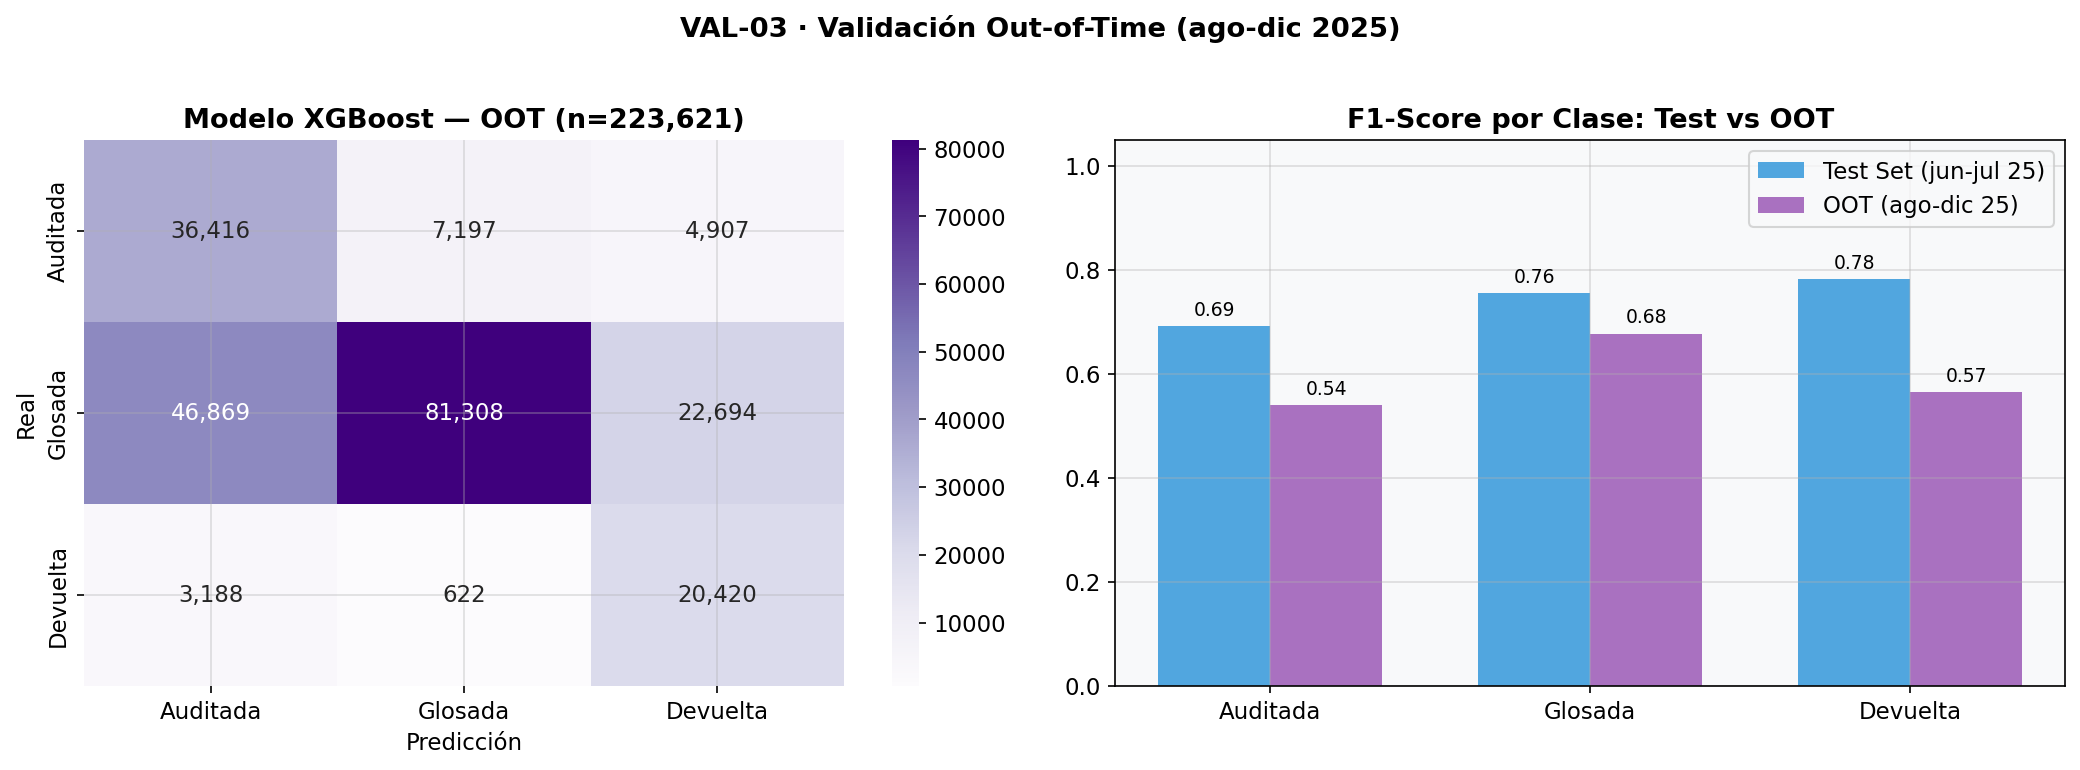

In [17]:
# Celda 11 — Visualización OOT: Confusion matrix + estabilidad temporal

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
class_names = [LABELS[i] for i in [0, 1, 2]]

# Confusion matrix OOT
cm_oot = confusion_matrix(y_true_oot, y_pred_oot)
sns.heatmap(cm_oot, annot=True, fmt=',d', cmap='Purples',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title(f'Modelo XGBoost — OOT (n={len(df_oot):,})')
axes[0].set_ylabel('Real')
axes[0].set_xlabel('Predicción')

# Barras de F1 por clase: Test vs OOT
f1_test_cls = f1_score(y_true, y_modelo, average=None)
f1_oot_cls = f1_score(y_true_oot, y_pred_oot, average=None)

x = np.arange(3)
width = 0.35
bars1 = axes[1].bar(x - width/2, f1_test_cls, width, label='Test Set (jun-jul 25)',
                    color='#3498db', alpha=0.85)
bars2 = axes[1].bar(x + width/2, f1_oot_cls, width, label='OOT (ago-dic 25)',
                    color='#9b59b6', alpha=0.85)
axes[1].set_xticks(x)
axes[1].set_xticklabels(class_names)
axes[1].set_title('F1-Score por Clase: Test vs OOT')
axes[1].set_ylim(0, 1.05)
axes[1].legend()

for bar in bars1:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{bar.get_height():.2f}', ha='center', fontsize=9)
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{bar.get_height():.2f}', ha='center', fontsize=9)

plt.suptitle('VAL-03 · Validación Out-of-Time (ago-dic 2025)', fontweight='bold', y=1.02)
plt.tight_layout()
save_fig('val_03_oot_confusion_estabilidad.png')
plt.show()

In [19]:
# Celda 12 — Exportar reporte JSON consolidado de validación

report = {
    "fecha_validacion": "2026-03-11",
    "modelo": "20260309_xgboost_v1.json",
    "features": len(FEATURE_COLS),
    "parte_a_test_set": {
        "periodo": "jun-jul 2025",
        "n_muestra": len(df_sample),
        "metricas_modelo": {
            "f1_macro": round(f1_modelo, 4),
            "recall_glosada": round(recall_glosada_modelo, 4),
            "balanced_accuracy": round(bal_acc_modelo, 4),
            "confusion_matrix": confusion_matrix(y_true, y_modelo).tolist(),
        },
        "metricas_ia_previa": {
            "n_con_prediccion": int(mask_ia.sum()),
            "f1_macro": round(float(f1_ia), 4) if f1_ia is not None else None,
            "recall_glosada": round(float(recall_glosada_ia), 4) if recall_glosada_ia is not None else None,
        } if f1_ia is not None else {"n_con_prediccion": 0},
    },
    "parte_b_oot": {
        "periodo": "ago-dic 2025",
        "n_facturas": len(df_oot),
        "distribucion_clases": {
            LABELS[cls]: int(cnt) for cls, cnt in
            pd.Series(y_true_oot).value_counts().sort_index().items()
        },
        "metricas_modelo": {
            "f1_macro": round(f1_oot, 4),
            "recall_glosada": round(recall_glosada_oot, 4),
            "balanced_accuracy": round(bal_acc_oot, 4),
            "confusion_matrix": confusion_matrix(y_true_oot, y_pred_oot).tolist(),
        },
        "metricas_ia_previa_oot": {
            "n_con_prediccion": int(mask_ia_oot.sum()),
            "f1_macro": round(float(f1_ia_oot), 4) if f1_ia_oot is not None else None,
        } if f1_ia_oot is not None else {"n_con_prediccion": 0},
        "degradacion_f1_pct": round(degradacion, 2),
    },
    "conclusion": (
        "ACEPTABLE" if degradacion < 5 else
        "MODERADA" if degradacion < 10 else
        "SIGNIFICATIVA"
    ),
    "figuras_generadas": [
        "val_01_confusion_matrices_comparacion.png",
        "val_02_metricas_por_clase_comparacion.png",
        "val_03_oot_confusion_estabilidad.png",
    ],
}

report_path = EVAL_DIR / '20260310_validacion_datos_reales.json'
with open(report_path, 'w', encoding='utf-8') as f:
    json.dump(report, f, indent=2, ensure_ascii=False)

f1_ia_str = f"{f1_ia:.4f}" if f1_ia is not None else "N/A"

print(f"✅ Reporte exportado: {report_path}")
print(f"\n{'='*70}")
print("RESUMEN FINAL DE VALIDACIÓN")
print("=" * 70)
print(f"""
  Parte A — Test Set (jun-jul 2025):
    Modelo XGBoost:  F1-macro={f1_modelo:.4f}  Recall Glosada={recall_glosada_modelo:.4f}
    IA Previa Savia: F1-macro={f1_ia_str}

  Parte B — Out-of-Time (ago-dic 2025):
    Modelo XGBoost:  F1-macro={f1_oot:.4f}  Recall Glosada={recall_glosada_oot:.4f}
    Degradación:     {degradacion:.1f}% → {report['conclusion']}

  Figuras: reports/figures/val_01..03_*.png
  Reporte: {report_path.name}
""")

✅ Reporte exportado: D:\Users\jcardonr\Documents\eafit\Codigo\reports\evaluations\20260310_validacion_datos_reales.json

RESUMEN FINAL DE VALIDACIÓN

  Parte A — Test Set (jun-jul 2025):
    Modelo XGBoost:  F1-macro=0.7432  Recall Glosada=0.7206
    IA Previa Savia: F1-macro=0.1697

  Parte B — Out-of-Time (ago-dic 2025):
    Modelo XGBoost:  F1-macro=0.5941  Recall Glosada=0.5389
    Degradación:     20.1% → SIGNIFICATIVA

  Figuras: reports/figures/val_01..03_*.png
  Reporte: 20260310_validacion_datos_reales.json

